**Clasificación de la afectación de incendios forestales en turberas de Tierra del Fuego mediante indicadores fisicoquímicos del suelo**

**Dataset:** Muestras_FyQ.xls

**Origen del dataset:** Repositorio Institucional CONICET Digital.

**Objetivo:** Desarrollar y evaluar modelos de Aprendizaje Automático que clasifiquen la severidad de quemado producida por el incendio forestal (baja, moderada o alta) de muestras de turberas de Tierra del Fuego a partir de sus propiedades fisicoquímicas

**Variable objetivo:** Burn_Severity

**Alumna:** Sandra Vargas | **Profesor:** Lic. Nicolás Caballero

# **Configuración del Entorno e Importación de Librerías**
Carga de las herramientas del ecosistema de Python para manipulación de datos, visualización y modelado.

In [76]:
# Librerías para manipulación y cálculo numérico
import numpy as np
import pandas as pd

# Librerías para exploración y visualización gráfica
import matplotlib.pyplot as plt
import seaborn as sns

# Módulos de Scikit-Learn (Preprocesamiento, Modelos y Métricas)
from sklearn.model_selection import train_test_split, cross_validate, GroupKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=UserWarning)

# Configuración estética de gráficos
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)
sns.set_theme(style='whitegrid')

---
# **Carga y visualización del dataset**
Carga del dataset a utilizar. Mediante el uso de la instrucción files.upload() podemos subir el archivo desde la computadora. Lee el archivo Excel y lo guarda en el DataFrame df. Luego se muestran las primeras 5 filas del DataFrame df para observar cómo están organizados los datos.

In [77]:
# Subimos el archivo
from google.colab import files
files.upload()

# Cargamos el dataset desde un archivo de Excel (.xlsx o .xls)
df = pd.read_excel("Muestras_FyQ.xlsx")

# Mostramos las primeras filas
df.head()

Saving Muestras_FyQ.xlsx to Muestras_FyQ (3).xlsx


,N,Turbera,Transecta,ID_SOBRE,Microtopography,Burn_Severity,pH,CE,DOB,MO,HD,BD,VWC,Ntotal,GWC
0,1,B1,T1,1,HUM,Low,4.33,83.8,0.00,97.279317,0.086667,0.025334,0.266383,NaN,10.514950
1,2,B1,T1,2,HUM,High,4.04,124.5,0.20,97.307769,0.095000,0.042672,0.482310,NaN,11.302761
2,3,B1,T1,3,HUM,Low,4.13,106.3,0.00,97.225250,0.049333,0.052435,0.610956,NaN,11.651685
3,4,B1,T1,4,HOL,High,3.96,174.9,0.75,90.004978,0.110667,0.081977,0.881211,NaN,10.749487
4,5,B1,T1,5,HUM,High,4.05,134.1,1.00,96.430347,0.088000,0.050289,0.551788,0.242676,10.972385


# Estructura del DataFrame y Resumen Estadístico

Inspección de la estructura del DataFrame, cantidad de filas y columnas, nombres, valores no nulos, tipos de datos y uso de memoria. Permite detectar valores faltantes y conocer las variables.

Presenta un resumen estadístico de las columnas numéricas, incluyendo cantidad de datos, promedio, desviación estándar, mínimo, máximo y cuartiles. Permite conocer la distribución y dispersión de los datos.

In [78]:
print(f"Dimensiones del dataset: {df.shape[0]} filas, {df.shape[1]} columnas\n")
df.info()
print("\n--- Estadísticas descriptivas — variables numéricas ---")
df.describe()
#display(df.describe().T)

Dimensiones del dataset: 231 filas, 15 columnas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231 entries, 0 to 230
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   N                231 non-null    int64  
 1   Turbera          231 non-null    object 
 2   Transecta        231 non-null    object 
 3   ID_SOBRE         231 non-null    int64  
 4   Microtopography  231 non-null    object 
 5   Burn_Severity    231 non-null    object 
 6   pH               231 non-null    float64
 7   CE               231 non-null    float64
 8   DOB              231 non-null    float64
 9   MO               231 non-null    float64
 10  HD               231 non-null    float64
 11  BD               231 non-null    float64
 12  VWC              231 non-null    float64
 13  Ntotal           62 non-null     float64
 14  GWC              231 non-null    float64
dtypes: float64(9), int64(2), object(4)
memory usage: 27.2+ KB



,N,ID_SOBRE,pH,CE,DOB,MO,HD,BD,VWC,Ntotal,GWC
count,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,62.000000,231.000000
mean,116.692641,18.424242,3.976277,229.244156,0.817857,95.221109,0.134004,0.054746,0.445134,0.469201,8.713745
std,67.831927,12.144497,0.157775,252.518764,0.755540,2.747157,0.055848,0.023811,0.133849,0.261667,2.058356
min,1.000000,1.000000,3.310000,64.700000,0.000000,84.938443,0.003333,0.020158,0.166395,0.192940,1.973260
25%,58.500000,9.000000,3.885000,112.700000,0.000000,93.667150,0.098500,0.039368,0.358103,0.261116,7.501173
50%,116.000000,17.000000,3.980000,160.800000,0.800000,96.179039,0.126033,0.047385,0.430253,0.375947,8.959818
75%,173.500000,26.000000,4.070000,196.650000,1.200000,97.304946,0.170000,0.060852,0.499458,0.652901,10.024111
max,235.000000,55.000000,4.470000,2760.000000,3.800000,98.481691,0.345667,0.138494,0.906503,1.243243,15.717095


El dataset contiene 231 registros y 15 variables.

Casi todas las columnas están completas (231 no nulos), excepto Ntotal, que solo tiene 62 valores (≈27%), por lo que cualquier análisis con esa variable pierde ~73% de los casos.

Variables fisicoquímicas homogéneas: pH es muy estable y ácido (media 3.98; rango 3.31–4.47). MO (materia orgánica) es muy alta y consistente (media 95.2%; rango 85–98.5%), características típicas de las turberas.

CE presenta fuerte asimetría (media 229 vs. mediana 161; máximo 2760), indicando valores extremos/outliers que conviene tratar. BD y HD también muestran colas hacia valores altos.

VWC media ≈0.45 (rango 0.17–0.91) y GWC media ≈8.7, con variabilidad apreciable entre muestras.

Variables categóricas balanceadas en estructura: Turbera, Transecta, Microtopography y Burn_Severity están completas, lo que permite comparaciones por grupo; conviene revisar su frecuencia antes de modelar.

En resumen el dataset presenta variables fisicoquímicas con distintos niveles de variabilidad que permiten explorar patrones y relaciones entre las características de las turberas. Los datos estan mayormente completos, pero con una variable bastante incompleta (Ntotal) y asimetría marcada en CE, , por lo que será necesario evaluar el tratamiento antes del modelado.

# Diagnóstico de valores nulos
Verifica la cantidad y el procentaje de valores nulos o faltantes en cada
columna del DataFrame. Permite identificar qué variables tienen datos incompletos y cuántos faltan en cada una.

In [79]:
faltantes = pd.DataFrame({
    'Cantidad': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df) * 100).round(2)
})

print("Valores faltantes por columna")
faltantes[faltantes['Cantidad'] > 0]

Valores faltantes por columna


,Cantidad,Porcentaje (%)
Ntotal,169,73.16


La columna Ntotal se elimina del análisis porque presenta un 73,16 % de valores faltantes (169 de 231 registros). Debido a la gran cantidad de datos ausentes, se decide no imputarlos para evitar introducir posibles sesgos o imprecisiones en el modelo de clasificación de la variable Burn_Severity.


In [80]:
# Eliminación de la columna 'Ntotal' ya que presenta más del 73% de valores nulos
if 'Ntotal' in df.columns:
    df = df.drop(columns=['Ntotal'])
    print("Columna 'Ntotal' eliminada con éxito.")
else:
    print("La columna 'Ntotal' ya no está presente en el DataFrame.")

# Verificamos las dimensiones actualizadas del dataset
print(f"Nuevas dimensiones del dataset: {df.shape[0]} filas, {df.shape[1]} columnas")

Columna 'Ntotal' eliminada con éxito.
Nuevas dimensiones del dataset: 231 filas, 14 columnas


In [81]:
#df.isnull().sum()
# Verificacmos que se haya eliminado la columna
if 'Ntotal' in df.columns:
    df = df.drop(columns=['Ntotal'])
    print("Columna 'Ntotal' eliminada con éxito.")
else:
    print("La columna 'Ntotal' ya no está presente en el DataFrame.")

La columna 'Ntotal' ya no está presente en el DataFrame.


# Diagnóstico de registros duplicados
Verificar la cantidad de filas duplicadas en el DataFrame, es decir, registros que se repiten completamente y luego visualiza los registros duplicados.


In [82]:
print("Cantidad de registros duplicados:", df.duplicated().sum())
if df.duplicated().sum() > 0:
    display(df[df.duplicated()])
else:
    print("No hay registros duplicados.")

Cantidad de registros duplicados: 0
No hay registros duplicados.


No hay registros duplicados por lo cual no es necesario eliminar registros para evitar observaciones repetidas.

# Análisis visual de distribuciones y relaciones


# Identificación de valores atípicos (outliers)

Se busca identificar observaciones extremas que puedan distorsionar las métricas o los algoritmos insensibles a la escala.
Para ello usamos Gráfico de Boxplot y regla del Rango Intercuartílico (IQR).

In [83]:
# Definimos las variables numéricas bajo estudio
numericas = ['pH', 'CE', 'DOB', 'MO', 'HD', 'BD', 'VWC', 'GWC']

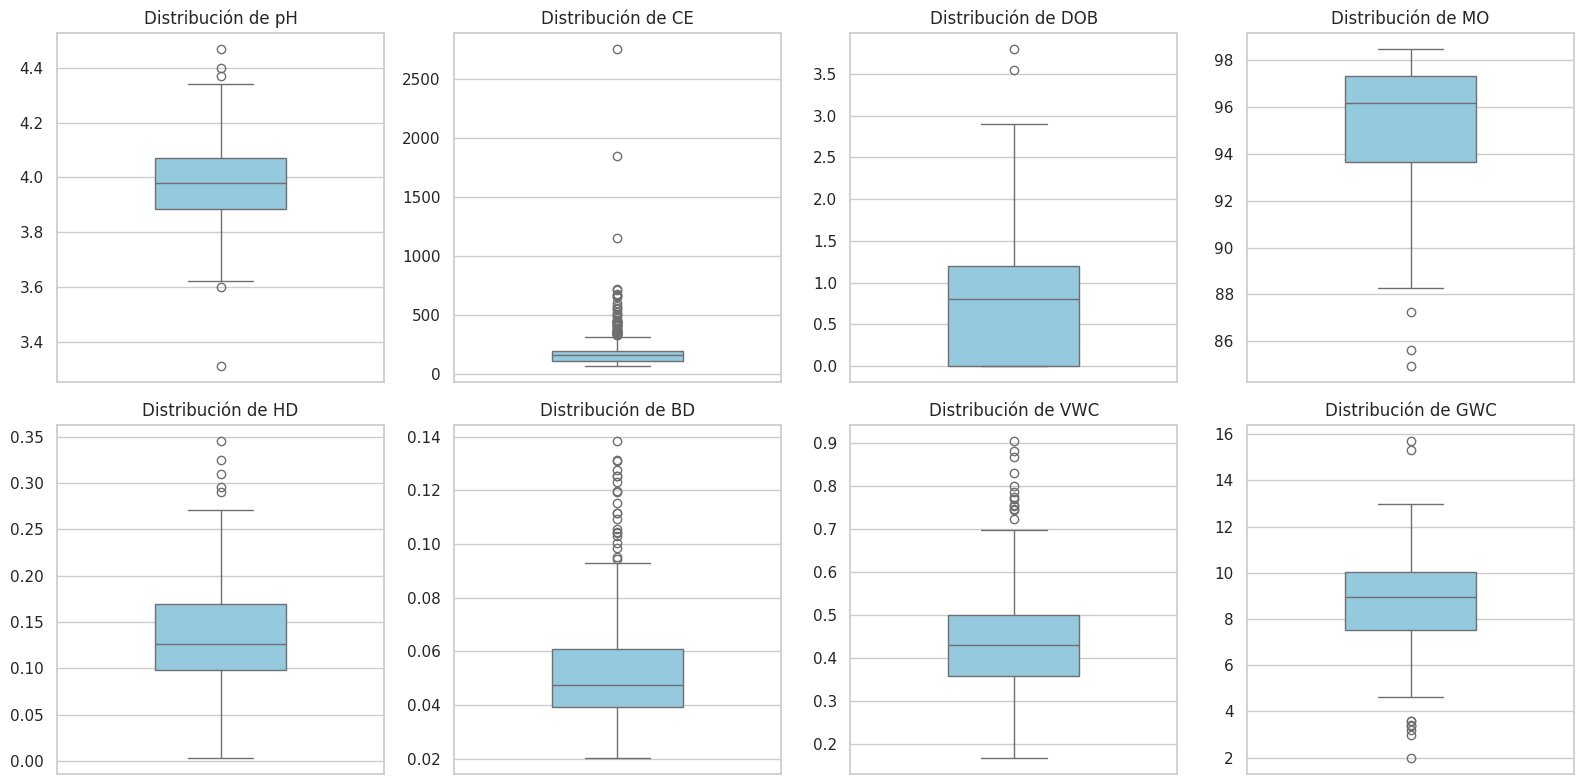

In [84]:
# Gráfico de Boxplot para las variables fisicoquímicas bajo estudio
plt.figure(figsize=(16, 8))

# Creamos una cuadrícula de subgráficos para las 8 variables numéricas
for i, col in enumerate(numericas, 1):
    plt.subplot(2, 4, i)
    # Graficamos el diagrama de caja usando Seaborn
    sns.boxplot(data=df, y=col, color='skyblue', width=0.4)
    plt.title(f'Distribución de {col}', fontsize=12)
    plt.ylabel('')

plt.tight_layout()
plt.show()

In [85]:
# Tabla con los límites formales y la cuantificación de los valores atípicos (outliers)
outliers_summary = []

for col in numericas:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    # Calculamos los límites formales de Tukey
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Identificamos las muestras fuera de los límites
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outliers_summary.append({
        'Variable': col,
        'Q1': round(q1, 4),
        'Q3': round(q3, 4),
        'IQR': round(iqr, 4),
        'Límite Inferior': round(lower_bound, 4),
        'Límite Superior': round(upper_bound, 4),
        'Cant. Outliers': len(outliers),
        'Porcentaje (%)': round((len(outliers) / len(df)) * 100, 2)
    })

# Convertimos a un DataFrame ordenado para facilitar la lectura
df_outliers = pd.DataFrame(outliers_summary)
display(df_outliers)

,Variable,Q1,Q3,IQR,Límite Inferior,Límite Superior,Cant. Outliers,Porcentaje (%)
0,pH,3.8850,4.0700,0.1850,3.6075,4.3475,5,2.16
1,CE,112.7000,196.6500,83.9500,-13.2250,322.5750,51,22.08
2,DOB,0.0000,1.2000,1.2000,-1.8000,3.0000,2,0.87
3,MO,93.6671,97.3049,3.6378,88.2105,102.7616,3,1.30
4,HD,0.0985,0.1700,0.0715,-0.0087,0.2772,5,2.16
5,BD,0.0394,0.0609,0.0215,0.0071,0.0931,21,9.09
6,VWC,0.3581,0.4995,0.1414,0.1461,0.7115,13,5.63
7,GWC,7.5012,10.0241,2.5229,3.7168,13.8085,9,3.90


La Conductividad Eléctrica (CE) presenta la mayor proporción de valores atípicos (22,08%), lo que sugiere variaciones importantes en la concentración de sales minerales. Le siguen la Densidad Aparente (BD) (9,09%) y el Contenido Volumétrico de Agua (VWC) (5,63%), que podrían reflejar cambios localizados en la estructura y humedad de la turba.

En cambio, la Densidad Óptica (DOB), la Materia Orgánica (MO) y el Hidrógeno de Campo (HD) presentan pocos valores atípicos, lo que indica distribuciones más homogéneas. En conjunto, los resultados muestran que algunas propiedades de las turberas tienen una mayor variabilidad que otras, posiblemente asociada a los efectos del fuego.

**Consideraciones**

Para tratar la pressencia de  los valores extremos de CE, DB y HD, aplicaremos RobustScaler

Usaremos transformar/log-transformar CE por su asimetría.

Realizamos un **gráfico de dispersión múltiple (pairplot)** que nos permitirá observar de manera simultánea todas las relaciones entre las variables físicoquímicas del suelo, con los puntos coloreados según la severidad del fuego (Burn_Severity).

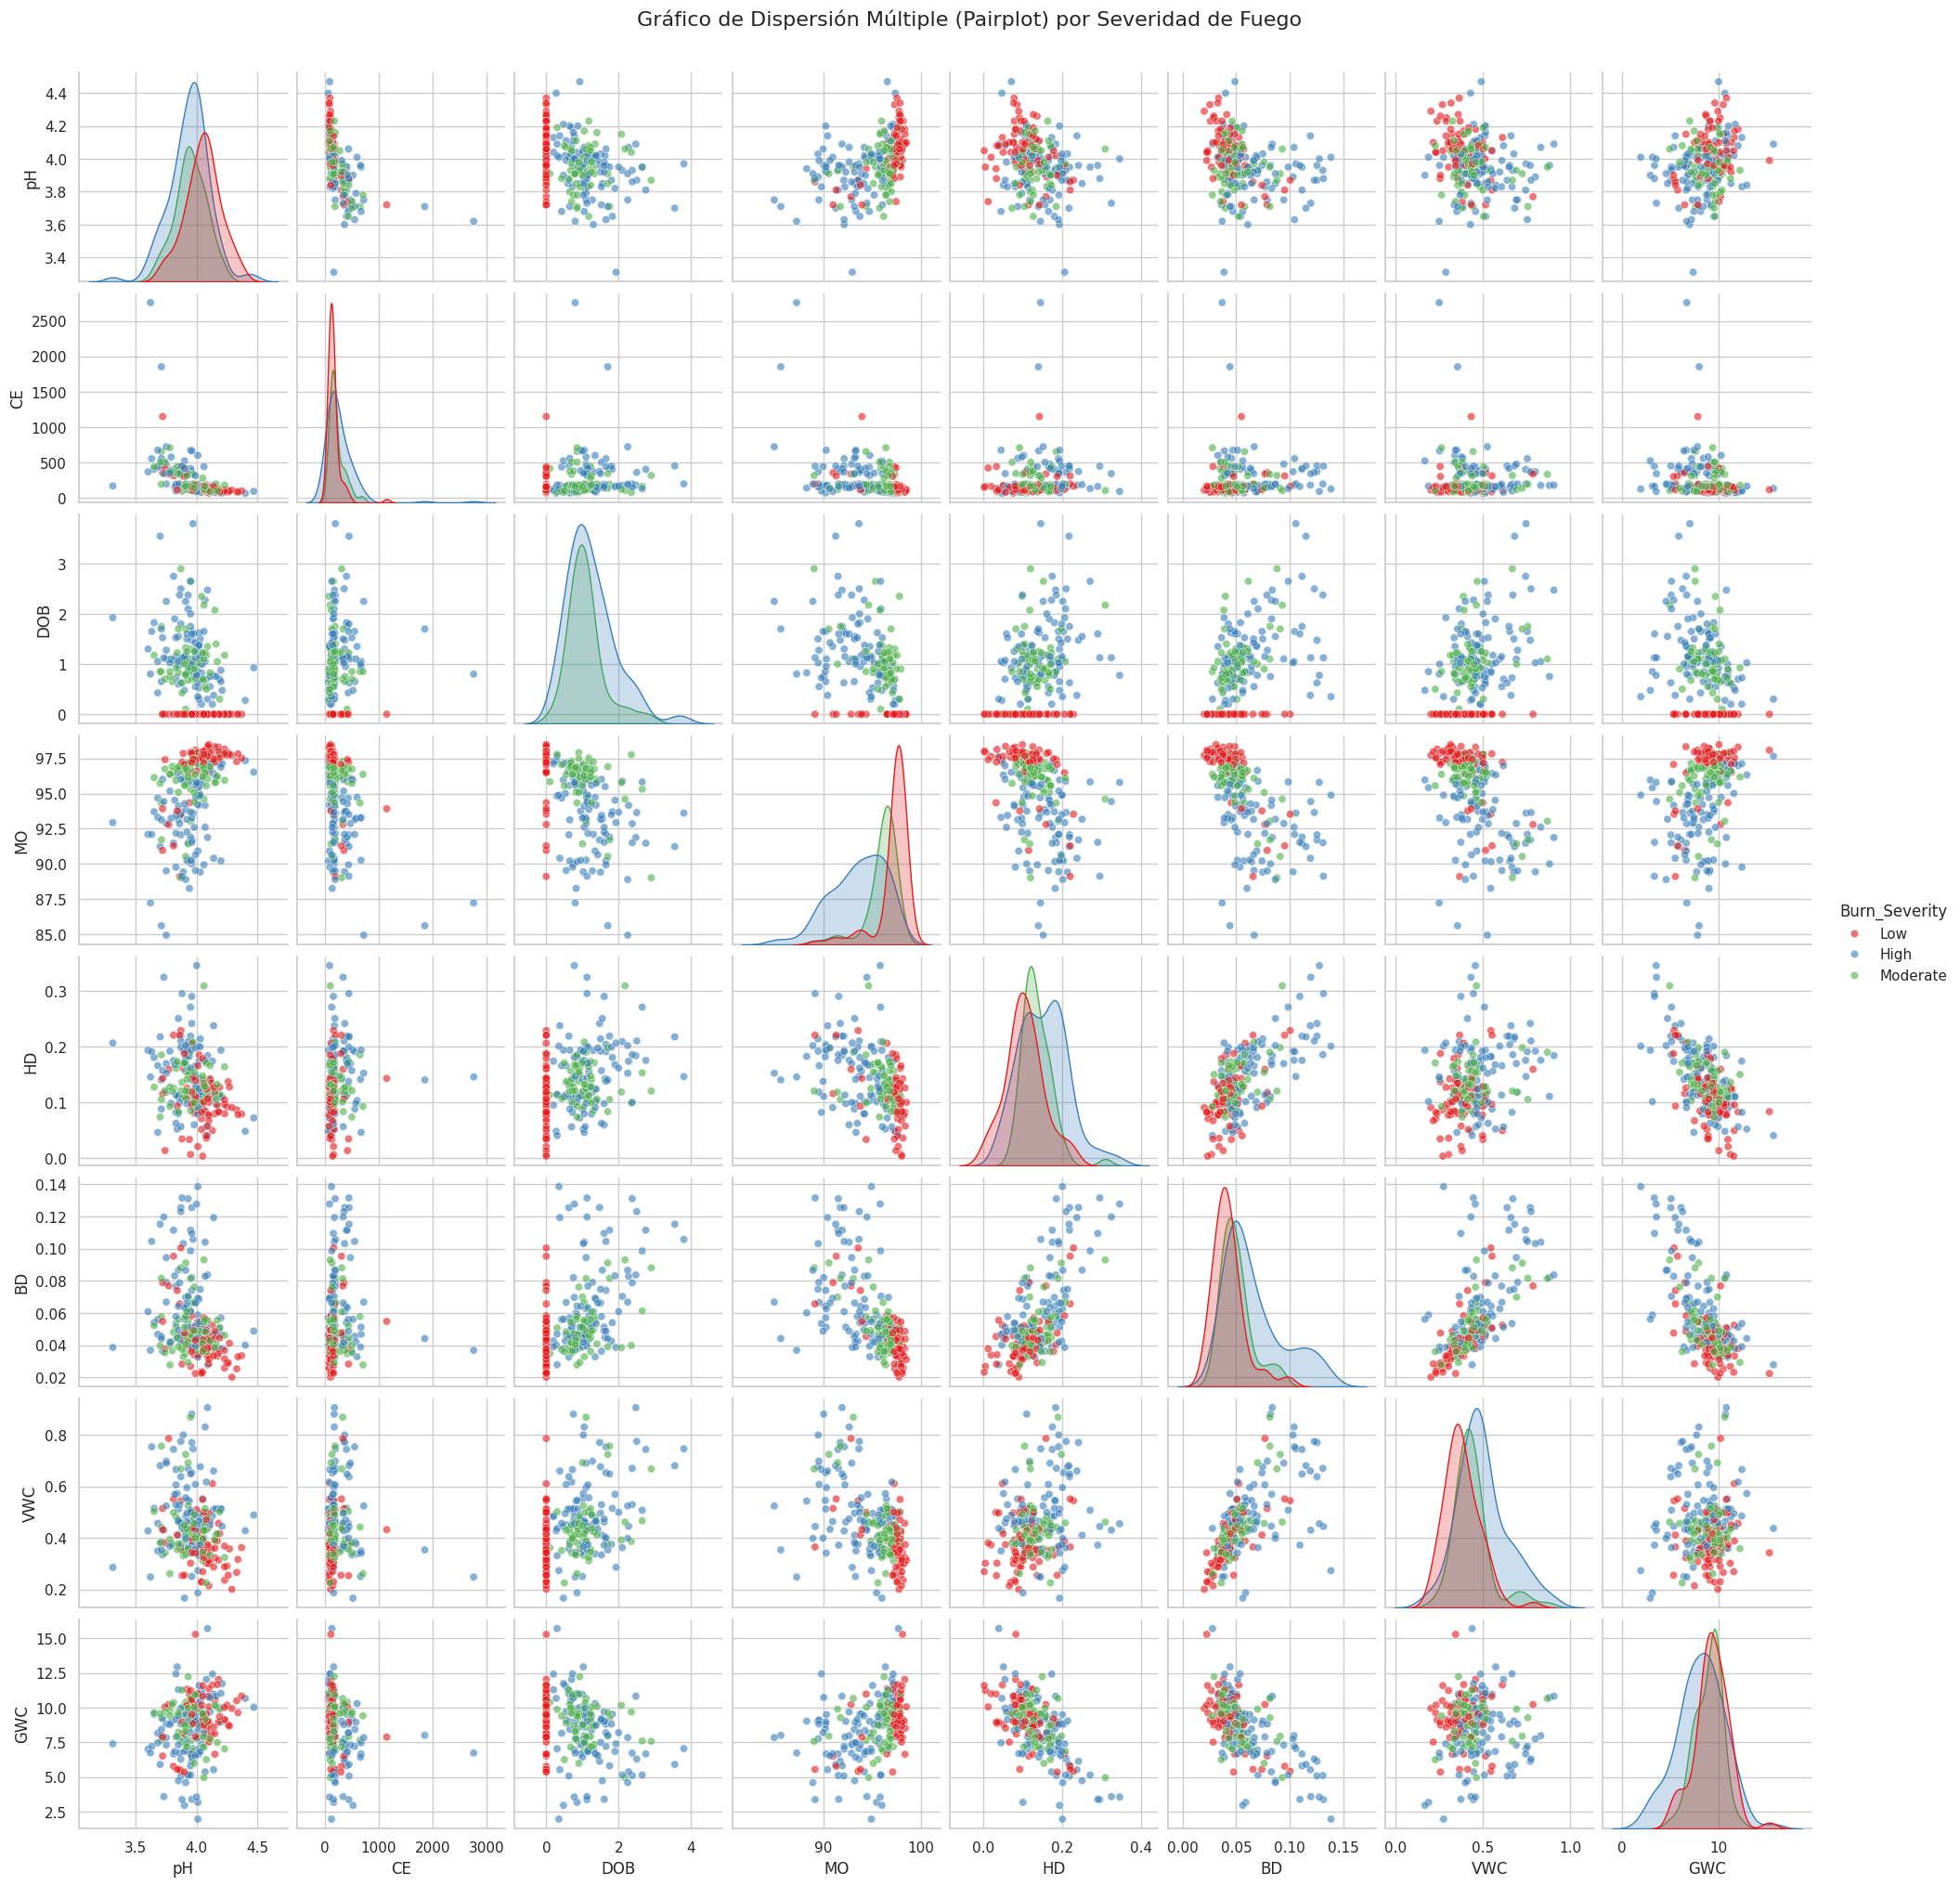

In [86]:
# Generamos el pairplot para analizar la interacción de todas las variables numéricas según la variable Burn_Severity

sns.pairplot(
    data=df[numericas + ['Burn_Severity']],
    hue='Burn_Severity',
    palette='Set1',
    diag_kind='kde',  # Muestra estimaciones de densidad kernel en la diagonal
    plot_kws={'alpha': 0.6}
)
plt.suptitle('Gráfico de Dispersión Múltiple (Pairplot) por Severidad de Fuego', y=1.02, fontsize=16)
plt.show()

El gráfico de dispersión múltiple nos permite visualizar que las muestras con alta severidad del fuego tienden a presentar menor contenido de materia orgánica (MO) y mayores valores de conductividad eléctrica (CE) y densidad aparente (BD). También se observa una relación positiva entre la densidad aparente y el contenido volumétrico de agua (VWC).

Aunque las clases de severidad baja y alta presentan algunas diferencias, existe cierto solapamiento y la severidad moderada actúa como una categoría de transición.

Estos patrones permiten identificar variables relevantes y justifican probar modelos de clasificación como Regresión Logística Multinomial y K-NN, evaluando cuál distingue mejor los niveles de severidad.

# Matriz de Correlación
Se utiliza la matriz únicamente sobre las características numéricas de entrada para detectar multicolinealidad entre los predictores, para evitar redundancia entre variables independientes antes de modelar.

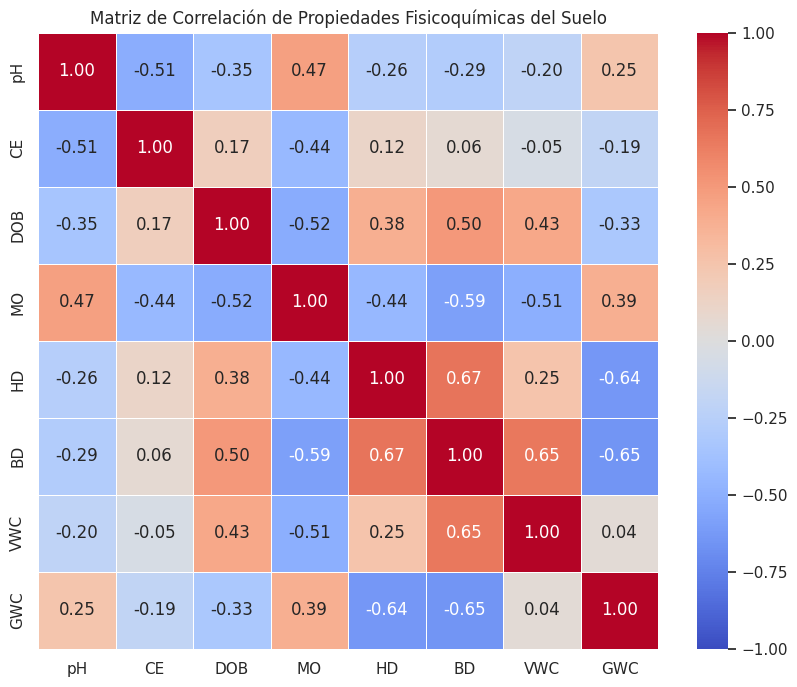

In [87]:
# Seleccionamos las columnas fisicoquímicas numéricas relevantes del dataset
#numericas = ['pH', 'CE', 'DOB', 'MO', 'HD', 'BD', 'VWC', 'GWC']

plt.figure(figsize=(10, 8))
# Calculamos la matriz de correlación
matriz_corr = df[numericas].corr()
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación de Propiedades Fisicoquímicas del Suelo")
plt.show()

La matriz muestra relaciones importantes entre las propiedades fisicoquímicas del suelo. Destaca la correlación positiva entre HD y BD (0,67), BD y VWC (0,65), y DOB y BD (0,50). En cambio, se observa una correlación negativa entre GWC y BD (-0,65), GWC y HD (-0,64), y MO y BD (-0,59). Además, el pH se relaciona positivamente con MO (0,47) y negativamente con CE (-0,51). Estas asociaciones permiten identificar variables relacionadas, aunque correlación no implica causalidad.

In [88]:
# Identificar variables con correlación bivariada superior a 0.80
umbral_corr = 0.60
columnas_correlacionadas = set()

for i in range(len(matriz_corr.columns)):
    for j in range(i):
        if abs(matriz_corr.iloc[i, j]) > umbral_corr:
            columna = matriz_corr.columns[i]
            columnas_correlacionadas.add(columna)

print("Variables correlacionadas a evaluar:", columnas_correlacionadas)


Variables correlacionadas a evaluar: {'GWC', 'VWC', 'BD'}


Vemos en  un gráfico de dispersión entre pH y materia orgánica (MO), coloreando los puntos según la severidad del fuego (Low, Moderate y High). Esto permitirá visualizar posibles diferencias y patrones entre las categorías e identificar si estas variables ayudan a distinguir los niveles de severidad para el modelo de clasificación.

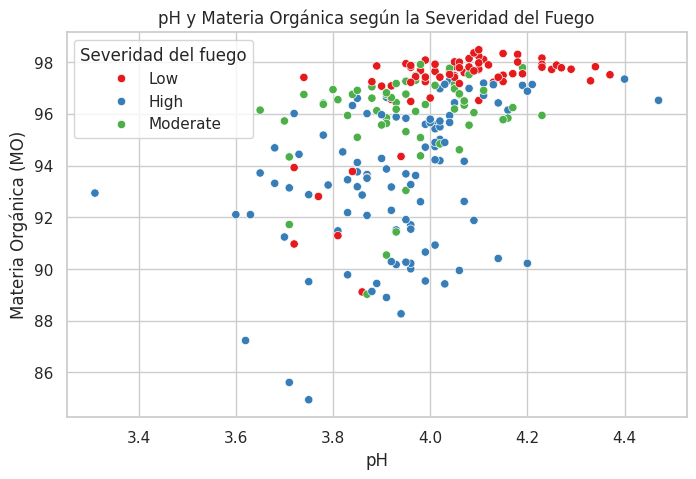

In [89]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='pH',
    y='MO',
    hue='Burn_Severity',
    palette='Set1'
)

plt.title('pH y Materia Orgánica según la Severidad del Fuego')
plt.xlabel('pH')
plt.ylabel('Materia Orgánica (MO)')
plt.legend(title='Severidad del fuego')
plt.show()

**¿Qué podemos analizar con este gráfico?**
- Si las categorías de severidad forman grupos diferenciados.
- Si hay superposición entre las clases Low, Moderate y High.
- Si el pH y la materia orgánica podrían ayudar a distinguir la severidad del fuego.

Importante: este gráfico permite explorar relaciones visuales, pero no demuestra por sí solo que estas variables permitan predecir correctamente la severidad. Eso se evaluará posteriormente con los modelos de clasificación.

# Distribución de la Variable Objetivo

In [90]:
# Proporción relativa (%) por categoría
#print(df['Burn_Severity'].value_counts(normalize=True) * 100)
print(pd.DataFrame({
    'Cantidad': df['Burn_Severity'].value_counts(),
    'Porcentaje (%)': df['Burn_Severity'].value_counts(normalize=True) * 100
}).round(2))

               Cantidad  Porcentaje (%)
Burn_Severity                          
High                100           43.29
Low                  71           30.74
Moderate             60           25.97


/tmp/ipykernel_1892/4204822770.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Burn_Severity', data=df, palette='Set2')


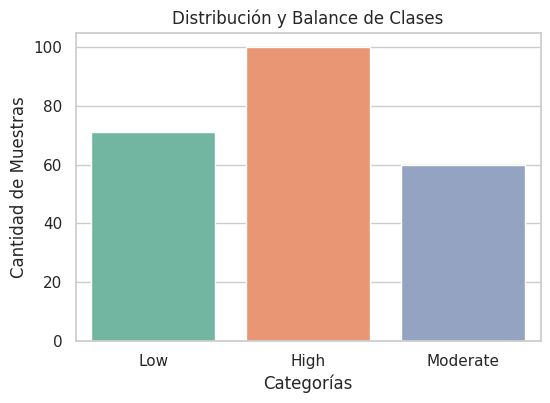

In [91]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Burn_Severity', data=df, palette='Set2')
plt.title('Distribución y Balance de Clases')
plt.xlabel('Categorías')
plt.ylabel('Cantidad de Muestras')
plt.show()

L presentan una distribución relativamente equilibrada, aunque existe un mayor número de muestras de alta severidad. No se observa un desequilibrio extremo, por lo que se puede avanzar con los modelos de clasificación, controlando su desempeño en cada categoría.

En este caso, como queremos clasificar la severidad del fuego en tres niveles (Low, Moderate y High), podemos convertir esas categorías en números para que el modelo pueda trabajar con ellas.

Como existe un orden entre los niveles (bajo, moderado y alto), podemos asignarles los valores 0, 1 y 2, respectivamente. De esta manera, mantenemos ese orden al preparar los datos para el entrenamiento.

In [92]:
# 1. Definir el diccionario de mapeo jerárquico
mapeo_severidad = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

# 2. Aplicar el mapeo sobre la columna objetivo
df['target'] = df['Burn_Severity'].map(mapeo_severidad)

# 3. Verificar el resultado y el balance de clases codificado
print("--- Conteo por clase codificada ---")
print(df['target'].value_counts())

--- Conteo por clase codificada ---
target
2    100
0     71
1     60
Name: count, dtype: int64


Si alguna fila tuviera un valor distinto a 'Low', 'Moderate' o 'High' (por ejemplo, un error tipográfico o valor nulo), .map() le asignará un valor NaN. Verificamos si quedaron nulo.

In [93]:
df['target'].isnull().sum()

np.int64(0)

In [94]:
if df['target'].isnull().sum() == 0:
    print("La columna 'target' no tiene valores faltantes (NaN).")
else:
    print(f"La columna 'target' tiene {df['target'].isnull().sum()} valores faltantes (NaN).")

La columna 'target' no tiene valores faltantes (NaN).


In [95]:
df

,N,Turbera,Transecta,ID_SOBRE,Microtopography,Burn_Severity,pH,CE,DOB,MO,HD,BD,VWC,GWC,target
0,1,B1,T1,1,HUM,Low,4.33,83.8,0.000,97.279317,0.086667,0.025334,0.266383,10.514950,0
1,2,B1,T1,2,HUM,High,4.04,124.5,0.200,97.307769,0.095000,0.042672,0.482310,11.302761,2
2,3,B1,T1,3,HUM,Low,4.13,106.3,0.000,97.225250,0.049333,0.052435,0.610956,11.651685,0
3,4,B1,T1,4,HOL,High,3.96,174.9,0.750,90.004978,0.110667,0.081977,0.881211,10.749487,2
4,5,B1,T1,5,HUM,High,4.05,134.1,1.000,96.430347,0.088000,0.050289,0.551788,10.972385,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226,231,I2,T1,26,HOL,Moderate,3.98,184.7,1.250,94.376552,0.099000,0.048900,0.491400,10.049053,1
227,232,I2,T2,27,HOL,Moderate,4.11,87.0,0.825,96.908964,0.166000,0.042882,0.333169,7.769382,1
228,233,I2,T3,28,HOL,Moderate,3.98,139.5,0.900,95.081641,0.154000,0.076128,0.456681,5.998894,1
229,234,I2,T4,29,HOL,Moderate,3.90,157.9,1.000,95.569935,0.171333,0.051130,0.448601,8.773663,1


In [96]:
df.to_csv('Muestras_FyQ_procesado.csv', index=False)
print("Copia guardada con éxito como 'Muestras_FyQ_procesado.csv'")

Copia guardada con éxito como 'Muestras_FyQ_procesado.csv'


In [97]:
from google.colab import files
files.download('Muestras_FyQ_procesado.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>